## LSB steganography using stegosphere

This notebook introduces Least Significant Bit steganography using the stegosphere library.

Make sure https://pypi.org/project/pillow/ is installed for this tutorial, as images are utilised.

In [6]:
!pip install pillow

Defaulting to user installation because normal site-packages is not writeable


Importing stegosphere, image handling, LSB embedding, and utilities!

In [24]:
import stegosphere
from stegosphere import image
from stegosphere.embeddings import LSB
from stegosphere import binary_to_data

Loading an image and reading it's pixels as a numpy.array!

In [25]:
img = image.ImageContainer('logo_small_stego.png')
px = img.read()

Let's extract a potential hidden payload, and inspect the first 10 bits.

In [26]:
payload = LSB.extract(px)
print(payload[:10])

0101011101


For further processing, a binary payload can be converted into a text using `binary_to_data` or into a file using `binary_to_file`

In [27]:
print(binary_to_data(payload).decode())

Welcome to stegosphere! This payload is hidden inside of the logo using Least Significant Bit steganography!
Stegosphere is a versatile library for both applying steganography (hiding data within media) and performing steganalysis (detecting hidden data).
It provides a flexible framework for any data representable as a NumPy array, including images, videos, audio and TTF fonts.
Furthermore, multi-file embedding, Hamming codes, payload compression and encryption are available,
as well as a research toolbox for evaluating method performance and security.


Besides extracting a payload from a file, also embedding is supported.
Again, we read the pixels of an existing image:

In [ ]:
img = image.ImageContainer('logo_small.png')
px = img.read()

Let's check the capacity in bits!

In [29]:
print(LSB.max_capacity(px))

196608


Defining a payload, and hiding it into an image!

In the background, the payload is converted into binary, and a header is added, so that the payload length can be automatically determined when extracting.

In [ ]:
payload = 'This is a secret payload, which will be hidden inside of the image!'
stego_image = LSB.embed(px, payload)
img.save('stego_lsb.png',stego_image)

Using the `visualizer` module, we can check for any visible differences in the original and the stego image

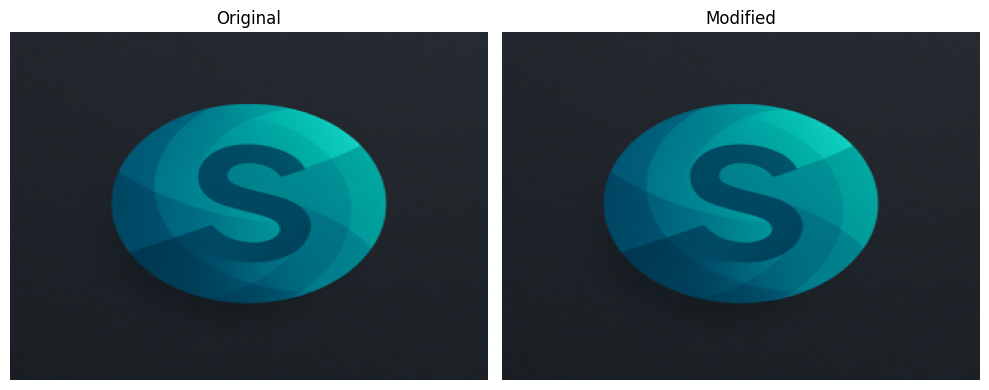

In [37]:
from stegosphere.analysis import visualizer
visualizer.show_side_by_side(px, stego_image)

As the payload was very small and LSB only changes the least significant bit (LSB), there is no visible difference!